# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd

from src.cat_modeling import cargar_datos
from src.transform import categorizar_en_cuantiles
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    pintar_matriz_correlacion, pintar_violin_plots 
)

# Cargar fichero de precios
simbolo = 'SPY'
intervalo = '1wk'
df, cols_exclude = cargar_datos(simbolo=simbolo, intervalo=intervalo, leer_cols_exclude=True)
df_clean = df.drop(columns=cols_exclude)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1037 entries, 2006-12-18 00:00:00-05:00 to 2026-10-26 00:00:00-04:00
Data columns (total 14 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Close_lag1_sma20_pct_diff_sma50     1037 non-null   float64
 1   HL_spread_lag1_sma5                 1037 non-null   float64
 2   Volume_lag1_pct_diff_sma20          1037 non-null   float64
 3   Close_lag1_min20_pct_diff_Open      1037 non-null   float64
 4   High_pct_diff_Open                  1037 non-null   float64
 5   Low_pct_diff_Open                   1037 non-null   float64
 6   Close_pct_diff_Open                 1037 non-null   float64
 7   Close_lag1_pct_diff_Open            1037 non-null   float64
 8   Close_lag1_sma50_pct_diff_Open      1037 non-null   float64
 9   Daily_return_lag1                   1037 non-null   float64
 10  Daily_return_lag1_var20_log         1037 non-null   float64


## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_lag1_sma20_pct_diff_sma50,1037.0,0.030550,0.053795,-0.224431,0.010835,0.042564,0.061878,0.130510
HL_spread_lag1_sma5,1037.0,0.032700,0.021124,0.009479,0.020538,0.026695,0.037992,0.196881
Volume_lag1_pct_diff_sma20,1037.0,0.014207,0.421817,-0.688562,-0.231067,-0.076698,0.148137,3.438468
Close_lag1_min20_pct_diff_Open,1037.0,-0.088761,0.055019,-0.306172,-0.117429,-0.084249,-0.054642,0.110148
High_pct_diff_Open,1037.0,0.015707,0.016018,0.000000,0.005396,0.011287,0.020696,0.151672
Low_pct_diff_Open,1037.0,-0.016122,0.018298,-0.219972,-0.021318,-0.010709,-0.004859,0.000000
Close_pct_diff_Open,1037.0,0.001802,0.023444,-0.174055,-0.009092,0.003146,0.013457,0.126323
Close_lag1_pct_diff_Open,1037.0,-0.000413,0.009048,-0.057207,-0.004062,-0.000802,0.002446,0.110148
Close_lag1_sma50_pct_diff_Open,1037.0,-0.041818,0.098222,-0.176266,-0.095837,-0.070359,-0.019342,0.616289
Daily_return_lag1,1037.0,0.002292,0.024988,-0.197934,-0.009499,0.003584,0.015216,0.132923


In [4]:
# Asimetrias
mostrar_asimetrias(df_clean)

HL_spread_lag1_sma5                   3.310262
High_pct_diff_Open                    3.117151
Volume_lag1_pct_diff_sma20            2.897591
Close_lag1_sma50_pct_diff_Open        2.735796
Close_lag1_pct_diff_Open              2.597732
Close_lag1_max20_pct_diff_Open_yeo    0.588824
Daily_return_lag1_var20_log           0.474778
HL_spread_lag1_log                    0.406166
High_lag1_pct_diff_Open_yeo          -0.071654
Close_pct_diff_Open                  -0.303654
Daily_return_lag1                    -0.648175
Close_lag1_min20_pct_diff_Open       -0.708667
Close_lag1_sma20_pct_diff_sma50      -1.872653
Low_pct_diff_Open                    -3.482761


Cont


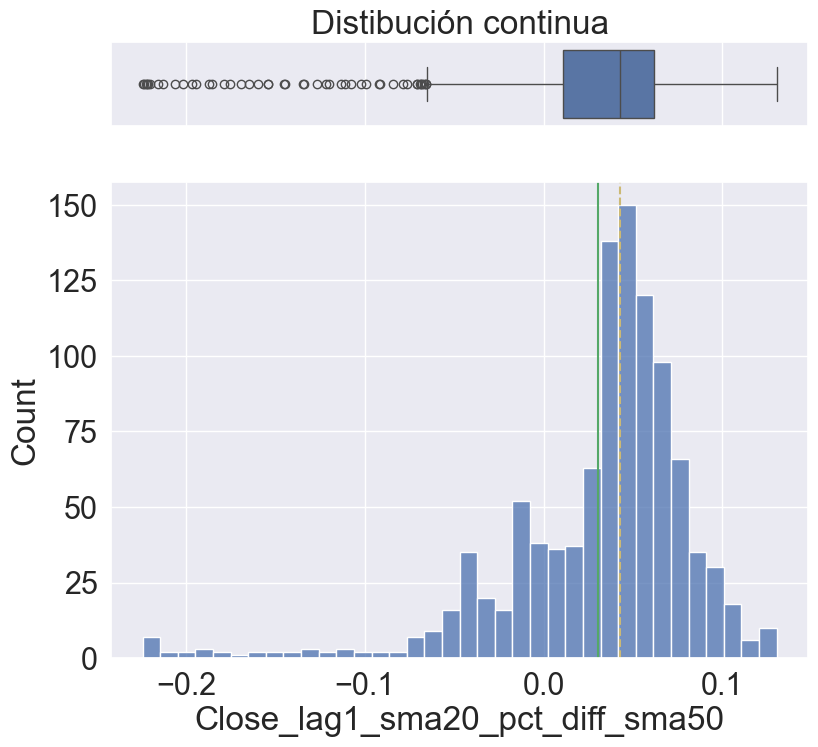

In [5]:
# Visualizar columna
col = 'Close_lag1_sma20_pct_diff_sma50'
pintar_columna(df_clean[col])

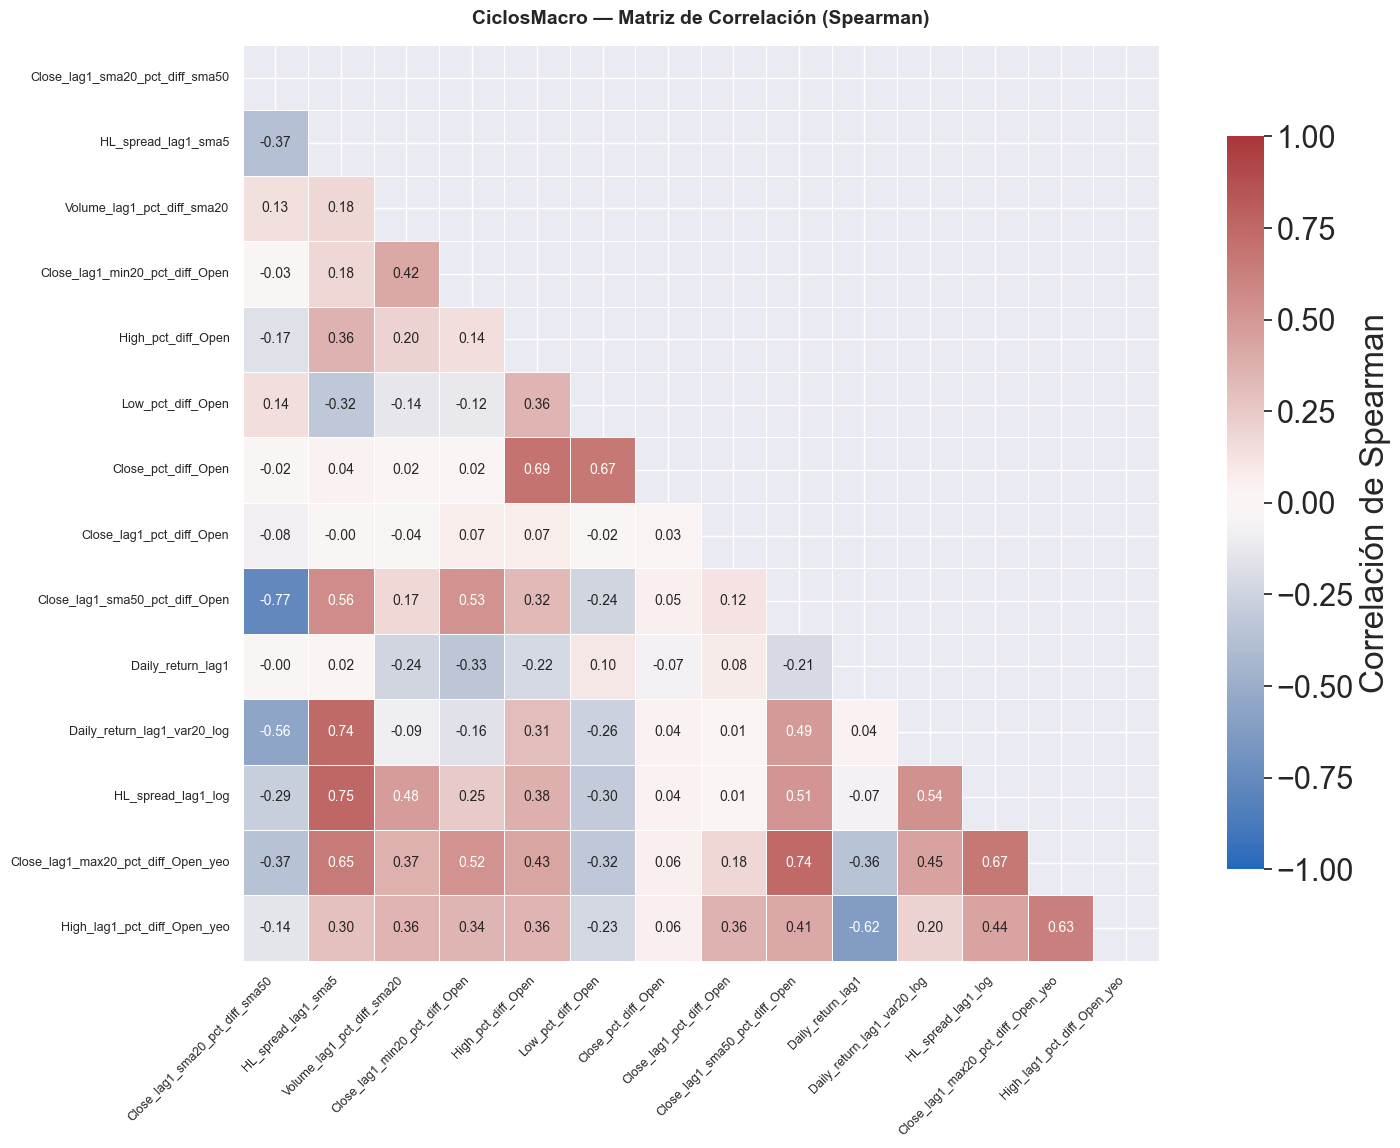

(                                    Close_lag1_sma20_pct_diff_sma50  \
 Close_lag1_sma20_pct_diff_sma50                            1.000000   
 HL_spread_lag1_sma5                                       -0.374206   
 Volume_lag1_pct_diff_sma20                                 0.133451   
 Close_lag1_min20_pct_diff_Open                            -0.026260   
 High_pct_diff_Open                                        -0.165487   
 Low_pct_diff_Open                                          0.142697   
 Close_pct_diff_Open                                       -0.020833   
 Close_lag1_pct_diff_Open                                  -0.083202   
 Close_lag1_sma50_pct_diff_Open                            -0.765782   
 Daily_return_lag1                                         -0.004490   
 Daily_return_lag1_var20_log                               -0.561660   
 HL_spread_lag1_log                                        -0.286627   
 Close_lag1_max20_pct_diff_Open_yeo                        -0.36

In [6]:
# Matriz de correlacion
pintar_matriz_correlacion(df_clean)

* `Close_pct_diff_Open` presenta escasa correlacion con los predictores, siendo el posible label mas debil.

## Analisis de labels

In [7]:
posibles_labels = ['High_pct_diff_Open', 'Low_pct_diff_Open', 'Close_pct_diff_Open']

objetivo = 'Close_pct_diff_Open'
objetivo_cat = f"{objetivo}_cat"

df_clean, tabla_bins = categorizar_en_cuantiles(
    df_clean, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=False
    )

# Se eliminan las posibles labels continuas
df_clean = df_clean.drop(columns=posibles_labels)

print("\n--- Rangos por Categoría ---")
print(tabla_bins)


--- Rangos por Categoría ---
   categoria  lim_inferior  lim_superior
0          1     -0.174055     -0.004605
1          2     -0.004605      0.009743
2          3      0.009743      0.126323


In [8]:
df_clean[objetivo_cat].value_counts()

Close_pct_diff_Open_cat
1    346
3    346
2    345
Name: count, dtype: int64

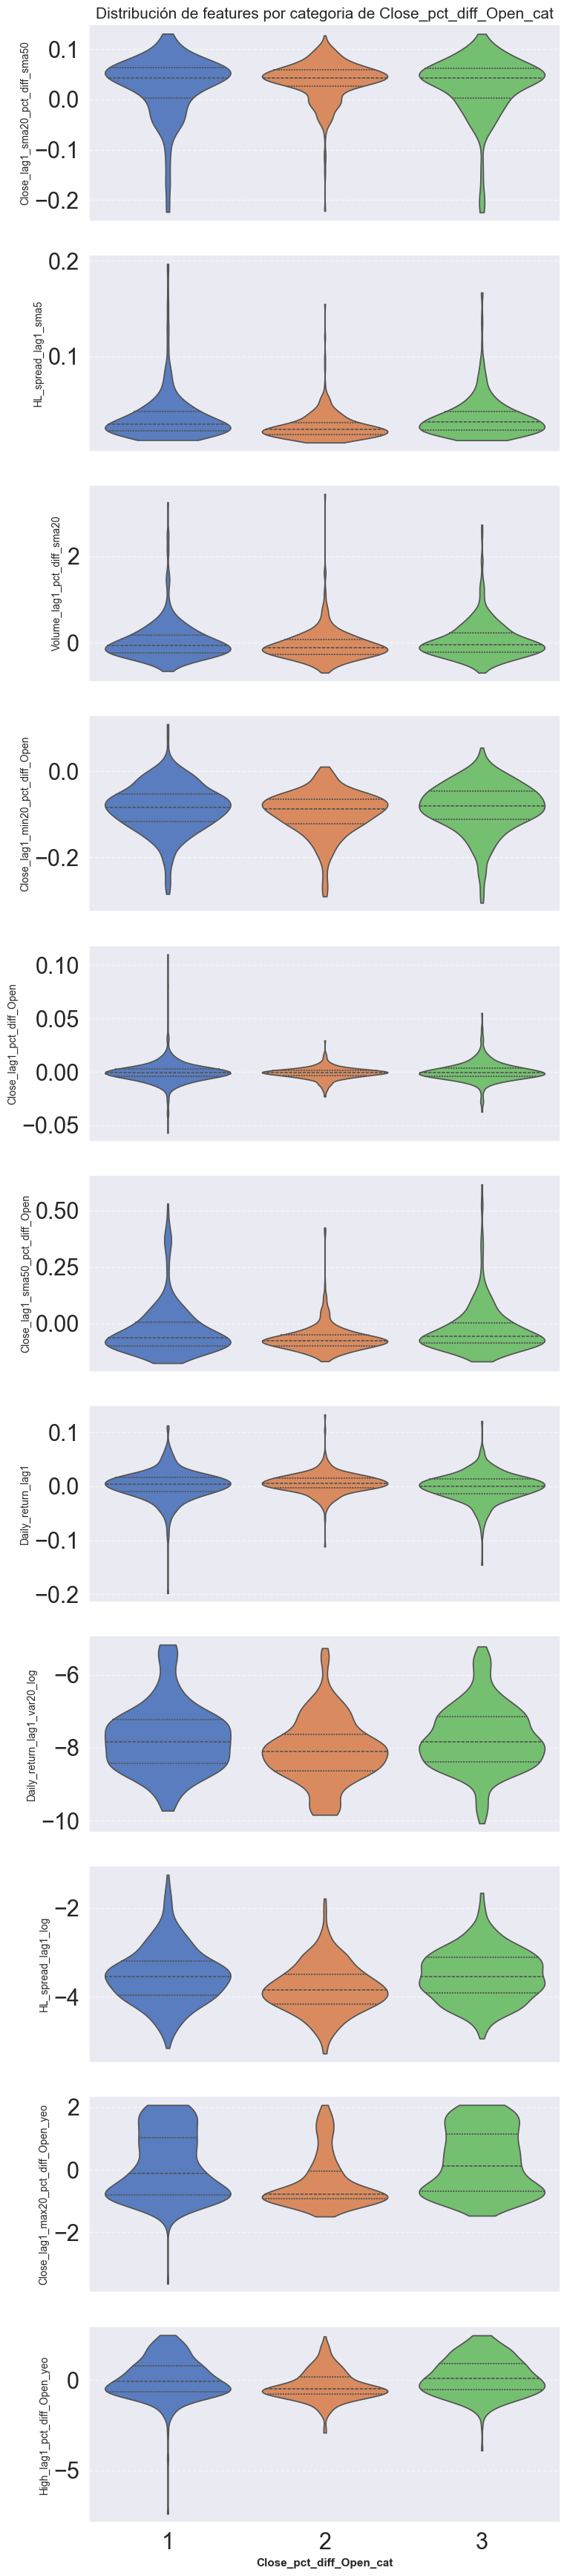

In [9]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_clean.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

pintar_violin_plots(
    df=df_clean,
    numeric_cols=numeric_cols,
    target_col=target_col
)

In [10]:
# Crear variable binaria: True si pertenece a la clase superior
df_clean['target_col_bin'] = (df_clean[objetivo_cat] ==3).astype(int)
df_clean['target_col_bin'].value_counts()

target_col_bin
0    691
1    346
Name: count, dtype: int64

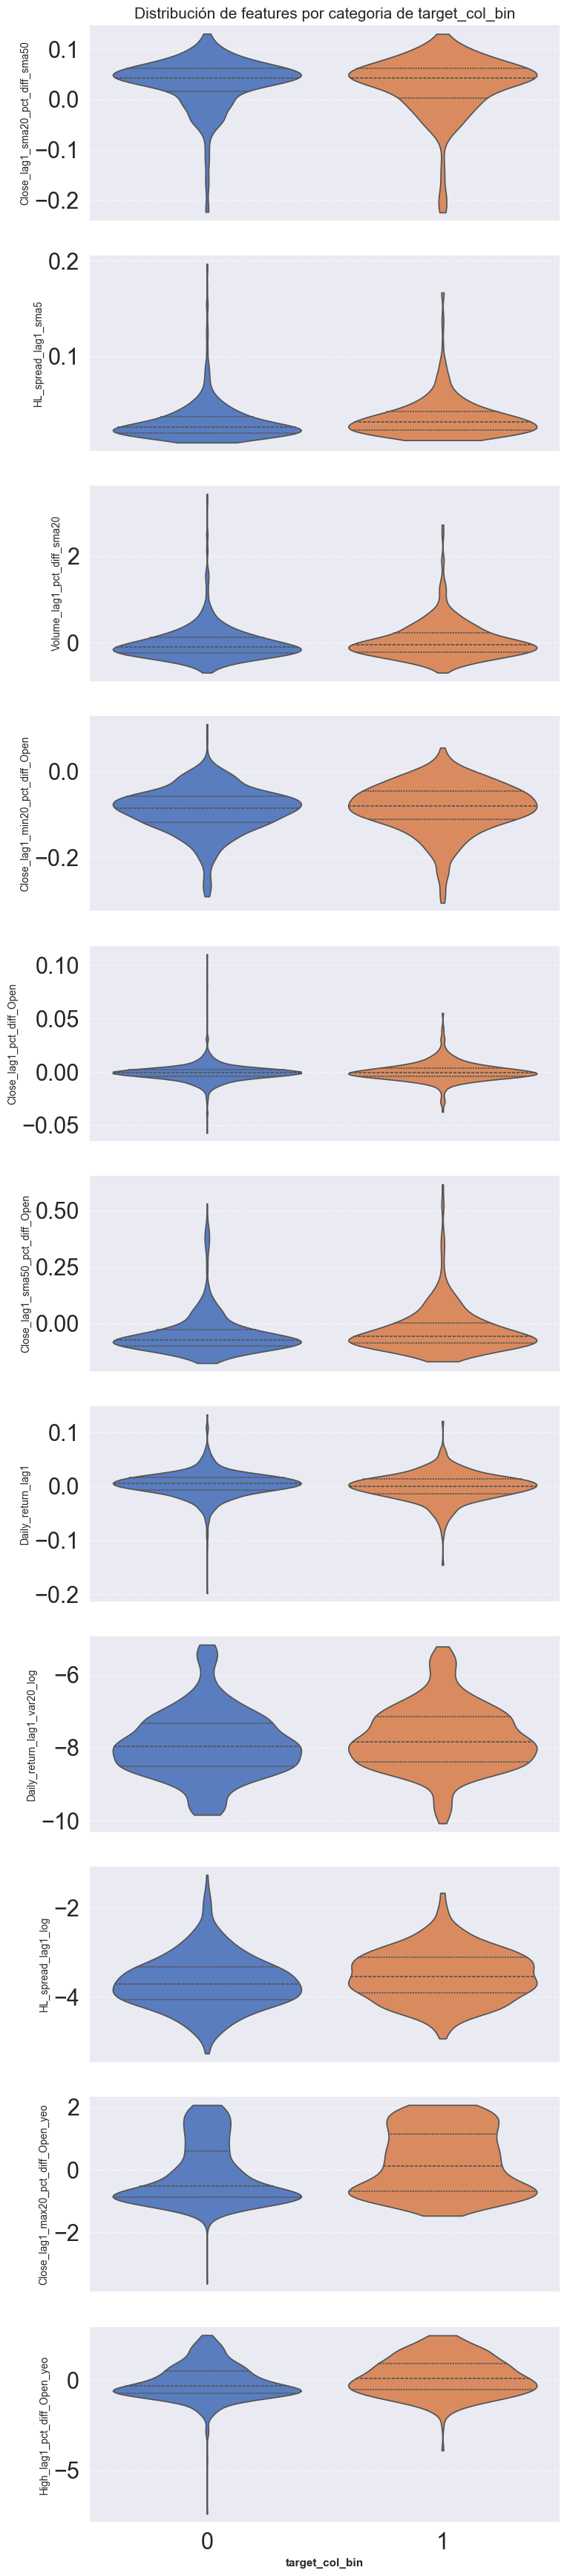

In [11]:
# Se elimina la variable objetivo multiclase
df_clean.drop(columns=[target_col], inplace=True)

# Graficos de violines
pintar_violin_plots(
    df=df_clean,
    numeric_cols=numeric_cols,
    target_col='target_col_bin'
)